<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and synthetic-input guide](README.md)

# 01 · Spatial autocorrelation depends on who counts as a neighbor

Do nearby sensors tend to have similar readings? The answer depends partly on the graph we use to define “nearby.” We will construct nearest-neighbor weights, inspect their direction and normalization, and reconstruct the worker's global Moran's I directly in SQL. Then we will widen the neighborhood while holding every location and reading fixed.

**Explicitly synthetic data:** 25 points on a slightly perturbed 5×5 grid, with a constructed gradient, deterministic variation and one central bump. Coordinates and readings have arbitrary units. These are not real sensor observations, geographic coordinates, or evidence of a real environmental pattern. The stored CSV and generation formula are documented in `fixtures/provenance.json`; no API or live-data mode is needed.

## Choose a neighborhood size

`K_NEIGHBORS` is an integer from **1 to 12**. Default **3** gives each sensor three outgoing nearest-neighbor links; the experiment uses **6**. Distances are Euclidean in this synthetic planar coordinate system. This is not a fixed-distance radius, and nearest-neighbor relationships need not be reciprocal.

`PERMUTATIONS` is an integer from **99 to 9,999**; default **499**. `SEED` is an integer from **0 to 2³²−1**; default **1729**. Keep both fixed for the neighborhood experiment. Restart Kernel → Run All after editing.

In [1]:
K_NEIGHBORS = 3  # Outgoing nearest neighbors per sensor; experiment: 6
PERMUTATIONS = 499  # Random value permutations on the fixed graph
SEED = 1729  # Fix the numerical runtime and this seed for reproducibility

In [2]:
import hashlib
import json
import os
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

assert type(K_NEIGHBORS) is int and 1 <= K_NEIGHBORS <= 12
assert type(PERMUTATIONS) is int and 99 <= PERMUTATIONS <= 9999
assert type(SEED) is int and 0 <= SEED < 2**32
manifest = json.loads(Path("fixtures/provenance.json").read_text())
fixture_hash = hashlib.sha256(Path("fixtures/sensors.csv").read_bytes()).hexdigest()
assert fixture_hash == manifest["sha256"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Synthetic 25-sensor layout · arbitrary planar/reading units · real PySAL worker · no real observations",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.93))
    plt.show()


previous_backend = os.environ.get("MPLBACKEND")
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline
os.environ["MPLBACKEND"] = "Agg"  # Headless worker imports must not inherit the notebook backend.

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-pysal/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-pysal/notebooks/pyproject.toml.

## Build weights from an explicit, stable input order

The literal Git launch pins the remote worker revision. `worker-constraints.txt` pins its tested numerical and protocol dependencies separately from this notebook's environment; no local worker checkout is used.

The worker buffers a whole table to build a spatial graph. Pass the same ordered rows to weights, summary and Moran's I. An explicit `id` carries sensor keys through the edge list; otherwise those keys are input positions. Set `value => 'reading'` explicitly because `y` already names a coordinate.

With row standardization, the outgoing weights for each non-island sum to one. For KNN each retained neighbor therefore receives `1/k`. The [KNN documentation](https://pysal.org/libpysal/v4.14.1/generated/libpysal.weights.KNN.html) notes that equal-distance ties are broken arbitrarily; we check this fixture for ties before interpreting membership.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pysal' (
 TYPE vgi,
 LOCATION 'uvx --python 3.14 --from git+https://github.com/Query-farm/vgi-pysal.git@b3ef7feed7e55d3b223cce73f417843bcd3caf24 --constraints worker-constraints.txt vgi-pysal'
);
CREATE TABLE sensors AS SELECT * FROM read_csv_auto('fixtures/sensors.csv');
CREATE TABLE edges AS
SELECT * FROM pysal.weights((SELECT sensor_id,x,y FROM sensors ORDER BY sensor_id),
 w_type=>'knn',k=>{{K_NEIGHBORS}},transform=>'r',id=>'sensor_id');
CREATE TABLE graph_summary AS
SELECT * FROM pysal.weights_summary((SELECT x,y FROM sensors ORDER BY sensor_id),
 w_type=>'knn',k=>{{K_NEIGHBORS}},transform=>'r');
CREATE TABLE worker_moran AS
SELECT * FROM pysal.moran((SELECT x,y,reading FROM sensors ORDER BY sensor_id),
 value=>'reading',w_type=>'knn',k=>{{K_NEIGHBORS}},transform=>'r',
 permutations=>{{PERMUTATIONS}},seed=>{{SEED}});

,Count


## Verify the graph before interpreting the statistic

Recompute Euclidean distances in SQL and compare the complete expected neighbor set with the worker's returned edges. Then inspect outgoing weight sums, nonreciprocal links and weak connectivity. **No islands** only means every node has a neighbor; it does not by itself establish that all nodes belong to one connected component.

The recursive query treats each edge as undirected only to count weak components. Moran's I below uses the original directed weights. Sensor **S12** is the fixed central example shown on the map.

In [4]:
%%sql
CREATE TABLE distances AS
SELECT a.sensor_id AS focal,b.sensor_id AS neighbor,
 sqrt(pow(a.x-b.x,2)+pow(a.y-b.y,2)) AS distance,
 row_number() OVER(PARTITION BY a.sensor_id ORDER BY
 pow(a.x-b.x,2)+pow(a.y-b.y,2),b.sensor_id) AS neighbor_rank
FROM sensors a CROSS JOIN sensors b WHERE a.sensor_id<>b.sensor_id;
CREATE TABLE graph_components AS
WITH RECURSIVE undirected AS (
 SELECT focal,neighbor FROM edges UNION SELECT neighbor,focal FROM edges
), reach(start,node) AS (
 SELECT sensor_id,sensor_id FROM sensors
 UNION
 SELECT r.start,e.neighbor FROM reach r JOIN undirected e ON e.focal=r.node
)
SELECT start AS sensor_id,min(node) AS component FROM reach GROUP BY start;

,Count


In [5]:
%%sql diagnostics <<
SELECT g.*,
 (SELECT count(DISTINCT component) FROM graph_components) AS weak_components,
 (SELECT count(*) FROM edges e LEFT JOIN edges r ON e.focal=r.neighbor AND e.neighbor=r.focal
  WHERE r.focal IS NULL) AS nonreciprocal_directed_links,
 (SELECT min(s) FROM (SELECT sum(weight) AS s FROM edges GROUP BY focal)) AS min_outgoing_sum,
 (SELECT max(s) FROM (SELECT sum(weight) AS s FROM edges GROUP BY focal)) AS max_outgoing_sum
FROM graph_summary g;

In [6]:
%%sql focal_neighbors <<
SELECT e.focal,e.neighbor,e.weight,d.distance,s.reading AS neighbor_reading
FROM edges e JOIN distances d USING(focal,neighbor) JOIN sensors s ON s.sensor_id=e.neighbor
WHERE e.focal='S12' ORDER BY d.distance;

,w_type,transform,n,n_links,pct_nonzero,n_islands,min_neighbors,max_neighbors,mean_neighbors,weak_components,nonreciprocal_directed_links,min_outgoing_sum,max_outgoing_sum
0,knn,R,25,75,12.0,0,3,3,3.0,1,7,1.0,1.0


,focal,neighbor,weight,distance,neighbor_reading
0,S12,S07,0.333333,0.935263,14.633071
1,S12,S11,0.333333,1.027754,14.677505
2,S12,S13,0.333333,1.048073,18.869842


For **25 fixed sensors**, `k=3` creates **75 directed links**, including **7 without a reverse link**. There are **0 islands** and **1 weak component(s)**. Every outgoing sum is one, and the full edge set agrees with the independent SQL nearest-neighbor calculation. Input fingerprint: `c315eb06b4c069de7c34217cb4cc1f046619c57455a4ebb7a1f61f48b50b09fe`.

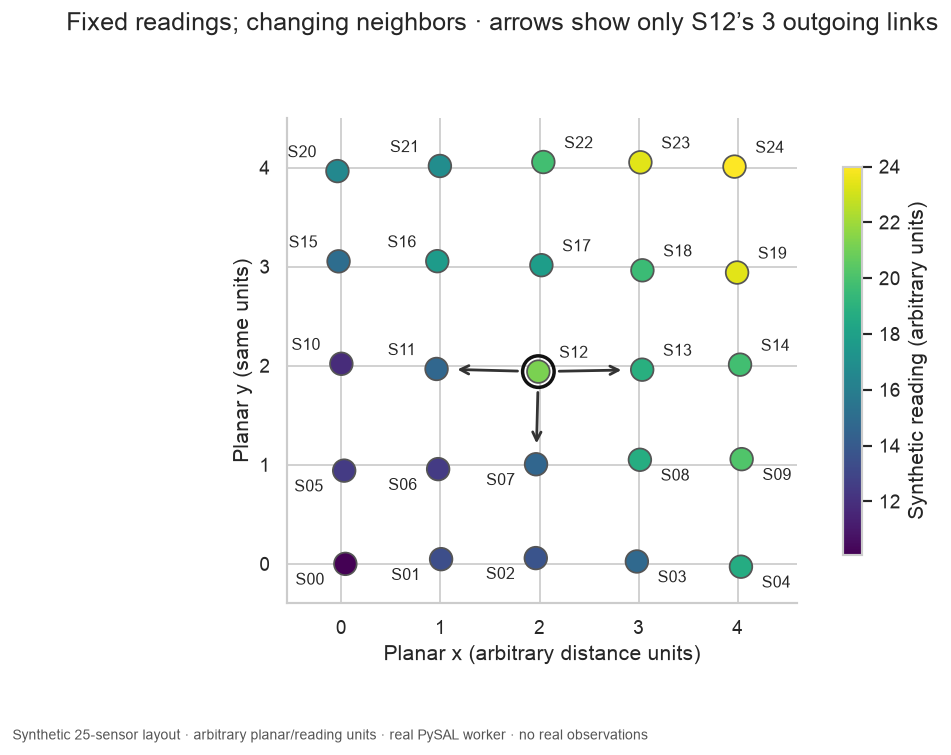

In [7]:
display(diagnostics)
display(focal_neighbors)
points = con.execute("SELECT * FROM sensors ORDER BY sensor_id").df()
assert points.sensor_id.is_unique and len(points) > K_NEIGHBORS
assert np.isfinite(points[["x", "y", "reading"]]).all().all() and points.reading.std() > 0
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT focal,round(distance,10),count(*) FROM distances GROUP BY focal,round(distance,10) HAVING count(*)>1)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT focal,neighbor FROM edges EXCEPT SELECT focal,neighbor FROM distances WHERE neighbor_rank<=?)",
        [K_NEIGHBORS],
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT focal,neighbor FROM distances WHERE neighbor_rank<=? EXCEPT SELECT focal,neighbor FROM edges)",
        [K_NEIGHBORS],
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM edges WHERE focal=neighbor OR weight IS NULL OR weight<=0").fetchone()[
        0
    ]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT focal,count(*) AS n,sum(weight) AS s FROM edges GROUP BY focal HAVING n<>? OR abs(s-1)>1e-10)",
        [K_NEIGHBORS],
    ).fetchone()[0]
    == 0
)
assert int(diagnostics.n_links.iloc[0]) == len(points) * K_NEIGHBORS
assert int(diagnostics.n.iloc[0]) == len(points) and int(diagnostics.n_islands.iloc[0]) == 0
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute("SELECT * FROM sensors ORDER BY sensor_id").fetchall(), separators=(",", ":")
    ).encode()
).hexdigest()
prose(
    f"For **{len(points)} fixed sensors**, `k={K_NEIGHBORS}` creates **{int(diagnostics.n_links.iloc[0])} directed links**, including **{int(diagnostics.nonreciprocal_directed_links.iloc[0])} without a reverse link**. There are **{int(diagnostics.n_islands.iloc[0])} islands** and **{int(diagnostics.weak_components.iloc[0])} weak component(s)**. Every outgoing sum is one, and the full edge set agrees with the independent SQL nearest-neighbor calculation. Input fingerprint: `{fingerprint}`."
)
fig, ax = plt.subplots(figsize=(8, 6))
focal = points[points.sensor_id == "S12"].iloc[0]
for row in focal_neighbors.itertuples():
    target = points[points.sensor_id == row.neighbor].iloc[0]
    ax.annotate(
        "",
        xy=(target.x, target.y),
        xytext=(focal.x, focal.y),
        arrowprops={"arrowstyle": "->", "color": "#333333", "lw": 1.6, "shrinkA": 12, "shrinkB": 12},
        zorder=2,
    )
sc = ax.scatter(
    points.x,
    points.y,
    c=points.reading,
    cmap="viridis",
    vmin=points.reading.min(),
    vmax=points.reading.max(),
    s=170,
    edgecolors="#555555",
    zorder=3,
)
ax.scatter([focal.x], [focal.y], s=330, facecolors="none", edgecolors="#111111", linewidths=2, zorder=4)
for row in points.itertuples():
    ax.annotate(
        row.sensor_id,
        (row.x, row.y),
        xytext=(12 if row.x >= focal.x else -12, 8 if row.y >= focal.y else -12),
        textcoords="offset points",
        ha="left" if row.x >= focal.x else "right",
        fontsize=9,
    )
fig.colorbar(sc, ax=ax, label="Synthetic reading (arbitrary units)", shrink=0.8)
ax.set(
    xlabel="Planar x (arbitrary distance units)",
    ylabel="Planar y (same units)",
    xlim=(-0.55, 4.6),
    ylim=(-0.4, 4.5),
    aspect="equal",
)
fig.suptitle(f"Fixed readings; changing neighbors · arrows show only S12’s {K_NEIGHBORS} outgoing links")
finish(fig)

## Reconstruct Moran's I from the returned weights

Center and scale each reading to `z` using the population standard deviation. Its spatial lag is `Wz`: the weighted mean of neighbor z-scores. With `S0 = sum(weights)`, global Moran's I is

**`(n / S0) × sum(z × Wz) / sum(z²)`**.

Our row-standardized graph has no islands, so `S0=n`. This is an association between readings and their neighborhood averages, not a causal effect or a sensor-quality score. The scatterplot's line is explicitly `I × z` through the origin; it is not a fitted predictive model. Quadrants indicate signs relative to the overall mean, not locally significant clusters.

In [8]:
%%sql
CREATE TABLE standardized AS
SELECT *, (reading-avg(reading) OVER())/stddev_pop(reading) OVER() AS z FROM sensors;
CREATE TABLE lags AS
SELECT a.sensor_id,a.x,a.y,a.reading,a.z,sum(e.weight*b.z) AS lag_z
FROM standardized a JOIN edges e ON a.sensor_id=e.focal
JOIN standardized b ON b.sensor_id=e.neighbor
GROUP BY a.sensor_id,a.x,a.y,a.reading,a.z;
CREATE TABLE sql_moran AS
SELECT count(*) AS n,(SELECT sum(weight) FROM edges) AS s0,
 count(*)/(SELECT sum(weight) FROM edges)*sum(z*lag_z)/sum(z*z) AS morans_i
FROM lags;

,Count


In [9]:
%%sql moran_result <<
SELECT w.statistic AS worker_morans_i,s.morans_i AS reconstructed_morans_i,
 w.expected AS randomization_expectation,w.p_value AS permutation_min_tail_p,
 w.n,w.permutations,s.s0 FROM worker_moran w CROSS JOIN sql_moran s;

,worker_morans_i,reconstructed_morans_i,randomization_expectation,permutation_min_tail_p,n,permutations,s0
0,0.706687,0.706687,-0.041667,0.002,25,499,25.0


The worker reports **I=0.706687**; SQL reconstructs **0.706687** from its exact graph. The randomization expectation is **-0.041667**. The returned permutation pseudo-p is **0.0020** with **499 permutations** and seed **1729**; the smallest possible value is **0.0020**. This is a computed property of deliberately patterned synthetic readings, not evidence about a real population.

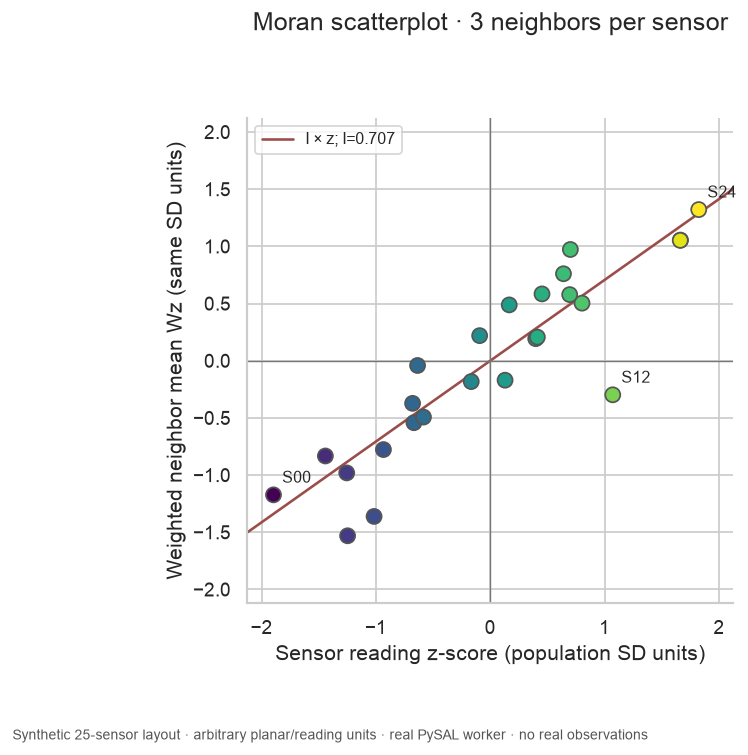

6257

In [10]:
display(moran_result)
r = moran_result.iloc[0]
assert abs(r.worker_morans_i - r.reconstructed_morans_i) < 1e-10
assert int(r.n) == len(points) and abs(r.s0 - len(points)) < 1e-10
assert abs(r.randomization_expectation + 1 / (len(points) - 1)) < 1e-10
assert 1 / (PERMUTATIONS + 1) <= r.permutation_min_tail_p <= 1
assert (
    abs(r.permutation_min_tail_p * (PERMUTATIONS + 1) - round(r.permutation_min_tail_p * (PERMUTATIONS + 1)))
    < 1e-8
)
lag_data = con.execute("SELECT * FROM lags ORDER BY sensor_id").df()
assert len(lag_data) == len(points) and abs(lag_data.z.mean()) < 1e-10
assert (
    con.execute(
        "SELECT count(*) FROM lags a WHERE lag_z<(SELECT min(b.z)-1e-10 FROM edges e JOIN standardized b ON e.neighbor=b.sensor_id WHERE e.focal=a.sensor_id) OR lag_z>(SELECT max(b.z)+1e-10 FROM edges e JOIN standardized b ON e.neighbor=b.sensor_id WHERE e.focal=a.sensor_id)"
    ).fetchone()[0]
    == 0
)
prose(
    f"The worker reports **I={r.worker_morans_i:.6f}**; SQL reconstructs **{r.reconstructed_morans_i:.6f}** from its exact graph. The randomization expectation is **{r.randomization_expectation:.6f}**. The returned permutation pseudo-p is **{r.permutation_min_tail_p:.4f}** with **{PERMUTATIONS} permutations** and seed **{SEED}**; the smallest possible value is **{1 / (PERMUTATIONS + 1):.4f}**. This is a computed property of deliberately patterned synthetic readings, not evidence about a real population."
)
fig, ax = plt.subplots(figsize=(7.8, 6))
ax.scatter(
    lag_data.z,
    lag_data.lag_z,
    c=lag_data.reading,
    cmap="viridis",
    vmin=points.reading.min(),
    vmax=points.reading.max(),
    s=75,
    edgecolors="#555555",
    zorder=3,
)
limit = max(abs(lag_data.z).max(), abs(lag_data.lag_z).max()) * 1.12
xx = np.array([-limit, limit])
ax.plot(xx, r.worker_morans_i * xx, color="#9b4d4a", label=f"I × z; I={r.worker_morans_i:.3f}")
ax.axhline(0, color="#777777", lw=0.8)
ax.axvline(0, color="#777777", lw=0.8)
selected = set(
    [
        points.loc[points.reading.idxmin(), "sensor_id"],
        points.loc[points.reading.idxmax(), "sensor_id"],
        "S12",
    ]
)
for row in lag_data.itertuples():
    if row.sensor_id in selected:
        ax.annotate(row.sensor_id, (row.z, row.lag_z), xytext=(5, 7), textcoords="offset points", fontsize=9)
ax.set(
    xlabel="Sensor reading z-score (population SD units)",
    ylabel="Weighted neighbor mean Wz (same SD units)",
    xlim=(-limit, limit),
    ylim=(-limit, limit),
    aspect="equal",
)
ax.legend(loc="upper left", fontsize=9)
fig.suptitle(f"Moran scatterplot · {K_NEIGHBORS} neighbors per sensor")
finish(fig)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "fixture_sha256": fixture_hash,
            "input_fingerprint": fingerprint,
            "k": K_NEIGHBORS,
            "permutations": PERMUTATIONS,
            "seed": SEED,
            "diagnostics": diagnostics.to_dict(orient="records"),
            "moran": moran_result.to_dict(orient="records"),
            "edges": con.execute("SELECT * FROM edges ORDER BY focal,neighbor").fetchall(),
            "focal_neighbors": focal_neighbors.to_dict(orient="records"),
        },
        indent=2,
    )
)

## Interpret the permutation output precisely

The pinned `esda 2.10.0` implementation globally permutes values over the fixed graph. Its returned `p_sim` uses **`(min(count(I_perm >= I_obs), count(I_perm < I_obs)) + 1) / (permutations + 1)`**. The worker exposes that value as `p_value`. It is a smaller-tail pseudo-p, not a conventional doubled two-sided p-value, a probability that the null is true, or a local test. The analytical `p_norm` is a different calculation and is not used here. See the [PySAL Moran documentation](https://pysal.org/esda/v2.9.0/generated/esda.Moran.html) for the underlying statistic and sidedness distinctions; the formula above was checked against the pinned 2.10.0 implementation.

The reference distribution assumes exchangeable values under spatial randomness. A constructed gradient deliberately violates that pattern; a low pseudo-p here mainly confirms that the calculation recognizes the pattern we put in. Neighborhood choice, sampling design and variable construction matter before any substantive inference.

## Experiment: widen the neighborhood

Change only `K_NEIGHBORS` from **3 to 6**. Predict twice as many outgoing links and half as much weight on each selected neighbor. For this smooth synthetic pattern, averaging a wider neighborhood may weaken local similarity; inspect the result rather than assuming Moran's I must decrease for every dataset.

Compare S12's arrows and neighbor table, the full graph diagnostics, the scatterplot and reconstructed I. The input hash, readings, coordinate limits, reading color scale, permutation count and seed must remain unchanged. A fixed seed does not make pseudo-p values across different graphs equivalent tests. Restore **3** afterwards. This experiment isolates the neighborhood convention; it does not select a scientifically correct neighborhood or validate a real-world causal explanation.

In [11]:
con.close()
if previous_backend is None:
    os.environ.pop("MPLBACKEND", None)
else:
    os.environ["MPLBACKEND"] = previous_backend

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)